In [ ]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (2,807 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependen

In [ ]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [ ]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [ ]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Overwriting setup.sh


In [ ]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


Saving resim2.jpeg to resim2 (2).jpeg
Oylama matrisi boyutu: (36, 300, 300)
En yuksek oy: 21
Bulunan cember sayisi: 3


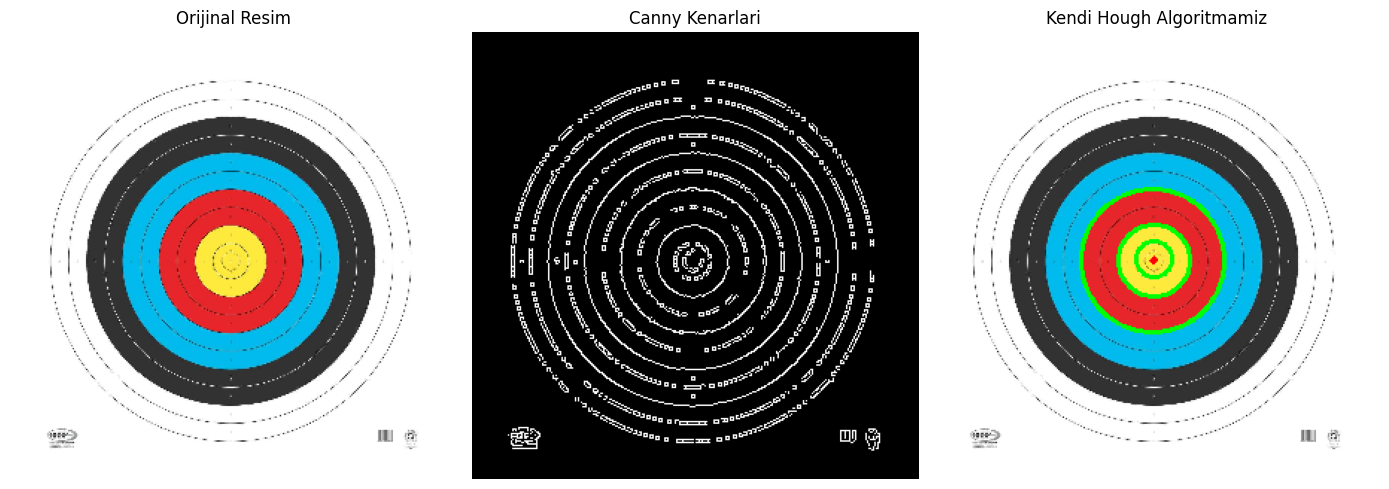

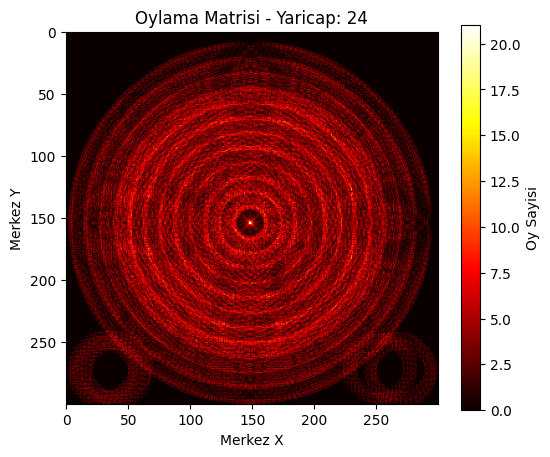

In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Resmi yukle
yuklenen = files.upload()
dosya_adi = list(yuklenen.keys())[0]

resim = cv2.imdecode(
    np.frombuffer(yuklenen[dosya_adi], np.uint8),
    cv2.IMREAD_COLOR
)

if resim is None:
    raise ValueError("Resim okunamadi!")

# Islem suresini azaltmak icin resmi kucult
h, w = resim.shape[:2]
if max(h, w) > 300:
    oran = 300 / max(h, w)
    resim = cv2.resize(resim, None, fx=oran, fy=oran)

# 2. Gri tona cevir ve kenarlari bul
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)
kenarlar = cv2.Canny(gri, 50, 150)

yukseklik, genislik = kenarlar.shape

# 3. Sin ve cos degerlerini onceden hesapla
acilar = np.deg2rad(np.arange(0, 360, 10))
sin_degerleri = np.sin(acilar)
cos_degerleri = np.cos(acilar)

# 4. Yarıcap araligini belirle
yaricaplar = np.arange(10, 81, 2)

# 5. 3 boyutlu oylama matrisi olustur
# Boyutlar: yaricap, merkez_y, merkez_x
oylama = np.zeros(
    (len(yaricaplar), yukseklik, genislik),
    dtype=np.uint16
)

# 6. Kenar piksellerini bul
ys, xs = np.where(kenarlar > 0)

# 7. Hough oylama islemi
for r_index, r in enumerate(yaricaplar):
    for x, y in zip(xs, ys):
        for sin_a, cos_a in zip(sin_degerleri, cos_degerleri):

            a = int(round(x - r * cos_a))
            b = int(round(y - r * sin_a))

            if 0 <= a < genislik and 0 <= b < yukseklik:
                oylama[r_index, b, a] += 1

print("Oylama matrisi boyutu:", oylama.shape)
print("En yuksek oy:", oylama.max())

# 8. Esik degerine gore cemberleri bul
esik = 20
adaylar = []

for r_index, r in enumerate(yaricaplar):
    merkezler = np.argwhere(oylama[r_index] >= esik)

    for b, a in merkezler:
        oy = int(oylama[r_index, b, a])
        adaylar.append((oy, a, b, int(r)))

# En cok oy alanlari once sirala
adaylar.sort(reverse=True)

# Birbirine cok yakin cemberleri ele
bulunan_cemberler = []

for oy, a, b, r in adaylar:
    tekrar = False

    for _, x2, y2, r2 in bulunan_cemberler:
        if np.hypot(a - x2, b - y2) < 12 and abs(r - r2) < 10:
            tekrar = True
            break

    if not tekrar:
        bulunan_cemberler.append((oy, a, b, r))

    if len(bulunan_cemberler) >= 20:
        break

# 9. Cemberleri orijinal resme ciz
sonuc = resim.copy()

for oy, a, b, r in bulunan_cemberler:
    cv2.circle(sonuc, (a, b), r, (0, 255, 0), 2)
    cv2.circle(sonuc, (a, b), 2, (0, 0, 255), -1)

print("Bulunan cember sayisi:", len(bulunan_cemberler))

# 10. Sonuclari goster
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Resim")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarlari")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("Kendi Hough Algoritmamiz")
plt.axis("off")

plt.tight_layout()
plt.show()

# 11. Oylama matrisinin bir kesitini goster
en_iyi_r = np.unravel_index(
    np.argmax(oylama), oylama.shape
)[0]

plt.figure(figsize=(6, 5))
plt.imshow(oylama[en_iyi_r], cmap="hot")
plt.colorbar(label="Oy Sayisi")
plt.title(f"Oylama Matrisi - Yaricap: {yaricaplar[en_iyi_r]}")
plt.xlabel("Merkez X")
plt.ylabel("Merkez Y")
plt.show()
